<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/10_Convolutional_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 10 — Neural Network yang Belajar Tepi dan Sudut: Pengantar *Convolutional Neural Network* (*Intro to Convolutional Neural Networks*)

**Buku:** *Grokking Deep Learning* — Andrew W. Trask (Manning, 2019)

Hingga kini setiap piksel terhubung ke setiap hidden node dengan bobot sendiri (*fully connected*). Bab ini memperkenalkan ide yang sangat berpengaruh: **menggunakan ulang bobot yang sama di banyak tempat**, yaitu ***convolutional layer***. Kita membangunnya dari nol dengan NumPy. Kode diambil dari repositori resmi buku, ditambah teori dan eksperimen pendukung (berlabel *Tambahan*).

---

## Daftar Isi
0. Persiapan
1. Menggunakan Ulang Bobot di Banyak Tempat
2. *Convolutional Layer*: Kernel yang Bergeser
3. Implementasi Sederhana dengan NumPy
4. Pelatihan CNN pada MNIST (Kode Buku)
5. Koreksi Tanda Update Kernel *(Tambahan)*
6. Melihat Kernel yang Dipelajari *(Tambahan)*
7. Tanya-Jawab Konsep dan Latihan
8. Ringkasan Bab

## 0. Persiapan

In [1]:
import os, gzip, pickle, urllib.request, warnings
import numpy as np
warnings.filterwarnings('ignore')

def load_mnist():
    """Memuat MNIST. Mencoba Keras dahulu (seperti di buku); bila tidak tersedia,
    memakai salinan MNIST di GitHub (mnielsen/neural-networks-and-deep-learning)."""
    try:
        from keras.datasets import mnist
        return mnist.load_data()
    except Exception:
        url = ('https://github.com/mnielsen/neural-networks-and-deep-learning/'
               'raw/master/data/mnist.pkl.gz')
        if not os.path.exists('mnist.pkl.gz'):
            urllib.request.urlretrieve(url, 'mnist.pkl.gz')
        with gzip.open('mnist.pkl.gz', 'rb') as f:
            tr, va, te = pickle.load(f, encoding='latin1')
        x_train = np.concatenate([tr[0], va[0]]).reshape(-1, 28, 28) * 255
        y_train = np.concatenate([tr[1], va[1]])
        return (x_train, y_train), (te[0].reshape(-1, 28, 28) * 255, te[1])

In [2]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = load_mnist()
print('data latih:', x_train.shape, '| data uji:', x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
data latih: (60000, 28, 28) | data uji: (10000, 28, 28)


---
## 1. Menggunakan Ulang Bobot di Banyak Tempat

Perhatikan sebuah fakta tentang gambar: **pola yang sama dapat muncul di mana saja**. Sebuah tepi vertikal atau sudut bisa berada di kiri atas gambar, atau tengah, atau kanan bawah. Pada jaringan *fully connected* (Bab 8–9), setiap hidden node punya bobot terpisah untuk setiap piksel, sehingga ia harus **mempelajari ulang pola yang sama untuk setiap posisi**, dari data yang terbatas, dan berisiko menghafal.

**Ide konvolusi:** pelajari **satu detektor kecil** (mis. detektor tepi 3×3) lalu **terapkan di setiap posisi** gambar. Bobot detektor yang **sama** dipakai ulang di semua tempat. Akibatnya:
1. **Jumlah parameter turun drastis** (kurang overfitting).
2. **Satu pola dipelajari dari seluruh posisi sekaligus** (data efektif lebih banyak).
3. Jaringan secara alami **tidak peka terhadap posisi** pola (*translation invariance*, setidaknya sebagian).

Dengan kata lain, konvolusi adalah **arsitektur yang menyaring noise** (ingat Bab 7: *"arsitektur yang hebat menyaring noise"*): ia memasukkan pengetahuan bahwa piksel yang berdekatan saling berhubungan dan pola yang sama berlaku di mana-mana.

In [3]:
# Tambahan (tidak ada di buku): jumlah parameter, layer padat vs layer konvolusi
piksel = 28 * 28
posisi = (28 - 3) * (28 - 3)            # 625 posisi jendela 3x3 (seperti di kode buku)
num_kernels = 16
hidden = posisi * num_kernels           # 10.000 node hidden

padat = piksel * hidden                 # setiap piksel ke setiap hidden node
konv  = 3 * 3 * num_kernels             # hanya bobot kernel
print(f'hidden layer berisi {hidden:,} node')
print(f'Layer padat (fully connected) : {padat:,} bobot')
print(f'Layer konvolusi (16 kernel 3x3): {konv:,} bobot  (~{padat // konv:,}x lebih sedikit)')
print(f'Bobot layer output (10.000 -> 10): {hidden * 10:,} (sama pada kedua jaringan)')

hidden layer berisi 10,000 node
Layer padat (fully connected) : 7,840,000 bobot
Layer konvolusi (16 kernel 3x3): 144 bobot  (~54,444x lebih sedikit)
Bobot layer output (10.000 -> 10): 100,000 (sama pada kedua jaringan)


**Interpretasi:** untuk menghasilkan 10.000 hidden node, layer padat membutuhkan ±7,8 juta bobot, sedangkan layer konvolusi hanya **144 bobot** karena kernel yang sama dipakai di 625 posisi. Inilah sumber efisiensi dan ketahanan konvolusi terhadap overfitting.

---
## 2. *Convolutional Layer*: Kernel yang Bergeser

Cara kerja satu **kernel** berukuran 3×3:
1. Ambil **potongan (*patch*) 3×3** dari gambar pada suatu posisi.
2. Hitung ***dot product*** potongan itu dengan 9 bobot kernel → **satu angka** (seberapa mirip potongan dengan pola kernel).
3. **Geser** jendela satu piksel, ulangi untuk semua posisi → hasilnya **peta fitur** (*feature map*).
4. Gunakan banyak kernel (di sini 16) → 16 peta fitur, masing-masing mendeteksi pola berbeda (tepi, sudut, garis…).
5. Ratakan semua peta fitur menjadi satu vektor (`hidden_size` = 10.000), lalu layer padat biasa memetakannya ke 10 kelas.

Ini sama dengan **sebuah neural network kecil (9 input → 16 output)** yang diterapkan berulang pada setiap potongan gambar, sesuai analogi bab.

Kita lihat efeknya dengan kernel **buatan tangan** (belum dilatih): detektor tepi vertikal dan horizontal.

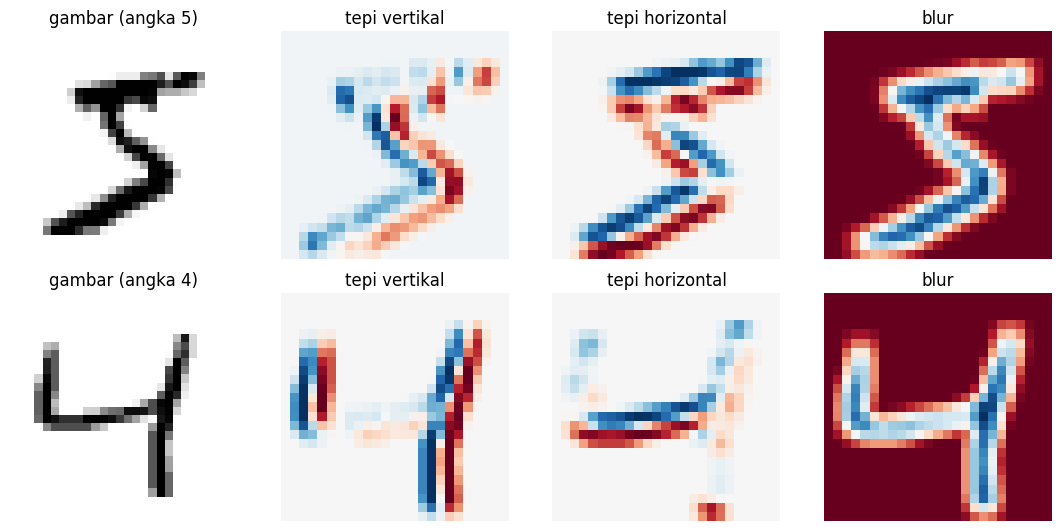

In [4]:
# Tambahan (tidak ada di buku): kernel buatan tangan pada gambar MNIST (jendela 3x3 seperti kode buku)
def get_image_section(layer, row_from, row_to, col_from, col_to):
    section = layer[:, row_from:row_to, col_from:col_to]
    return section.reshape(-1, 1, row_to - row_from, col_to - col_from)

def expand_batch(layer_0, kernel_rows=3, kernel_cols=3):
    """layer_0: (batch, 28, 28) -> (batch*625, 9) potongan 3x3 yang diratakan (logika kode buku)."""
    sects = list()
    for row_start in range(layer_0.shape[1] - kernel_rows):
        for col_start in range(layer_0.shape[2] - kernel_cols):
            sects.append(get_image_section(layer_0, row_start, row_start + kernel_rows,
                                           col_start, col_start + kernel_cols))
    expanded_input = np.concatenate(sects, axis=1)
    es = expanded_input.shape
    return expanded_input.reshape(es[0] * es[1], -1), es

kernel_vert = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)     # tepi vertikal
kernel_hor  = kernel_vert.T                                                    # tepi horizontal
kernel_blur = np.ones((3, 3)) / 9                                              # perataan (blur)

fig, axes = plt.subplots(2, 4, figsize=(11, 5.4))
for r, idx in enumerate([0, 2]):
    img = (x_train[idx] / 255.0)[None, :, :]
    flat, es = expand_batch(img)
    axes[r, 0].imshow(img[0], cmap='gray_r'); axes[r, 0].set_title(f'gambar (angka {y_train[idx]})')
    for c, (nm, k) in enumerate([('tepi vertikal', kernel_vert), ('tepi horizontal', kernel_hor), ('blur', kernel_blur)]):
        fmap = flat.dot(k.reshape(9)).reshape(25, 25)                          # peta fitur 25x25
        axes[r, c + 1].imshow(fmap, cmap='RdBu'); axes[r, c + 1].set_title(nm)
    for a in axes[r]: a.axis('off')
plt.tight_layout(); plt.show()

**Interpretasi:** kernel tepi vertikal menyala (merah/biru kuat) di bagian gambar yang berubah dari gelap ke terang secara horizontal, yaitu tepi vertikal angka; kernel horizontal menyorot tepi horizontal; blur hanya memperhalus gambar. Pada pelatihan sebenarnya, **kernel tidak dibuat tangan**: nilainya dipelajari oleh *gradient descent* agar menemukan pola yang berguna untuk klasifikasi.

---
## 3. Implementasi Sederhana dengan NumPy

Fungsi `get_image_section` mengambil potongan 3×3 untuk **seluruh gambar dalam batch sekaligus**. Perhatikan alur *shape* pada satu batch kecil (2 gambar):

In [5]:
# Tambahan (tidak ada di buku): alur shape pada konvolusi (batch 2 gambar, 16 kernel)
kernels_demo = np.random.RandomState(0).randn(9, 16) * 0.1
batch = x_train[:2].reshape(2, 28, 28) / 255.0

flat, es = expand_batch(batch)
kernel_output = flat.dot(kernels_demo)
layer_1 = np.tanh(kernel_output.reshape(es[0], -1))

print('expanded_input (batch, posisi, 3, 3) :', es)
print('flattened_input (batch*posisi, 9)    :', flat.shape)
print('kernel_output (batch*posisi, kernel) :', kernel_output.shape)
print('layer_1 (batch, posisi*kernel)       :', layer_1.shape, '= 625 x 16 = 10.000 hidden node')

# Cek: ekstraksi potongan buku identik dengan sliding window NumPy (untuk 25x25 posisi pertama)
from numpy.lib.stride_tricks import sliding_window_view
swv = sliding_window_view(batch, (3, 3), axis=(1, 2))[:, :25, :25]       # (2, 25, 25, 3, 3)
print('identik dengan sliding_window_view?', np.allclose(swv.reshape(2 * 625, 9), flat))

expanded_input (batch, posisi, 3, 3) : (2, 625, 3, 3)
flattened_input (batch*posisi, 9)    : (1250, 9)
kernel_output (batch*posisi, kernel) : (1250, 16)
layer_1 (batch, posisi*kernel)       : (2, 10000) = 625 x 16 = 10.000 hidden node
identik dengan sliding_window_view? True


**Interpretasi:**
- `flattened_input` berisi **setiap potongan 3×3 dari setiap gambar** (batch × 625 potongan, masing-masing 9 angka).
- Satu perkalian matriks dengan `kernels` (9×16) menghitung **semua kernel pada semua posisi sekaligus**.
- `reshape` meratakan hasilnya menjadi satu vektor 10.000 elemen per gambar, yang masuk ke layer padat ke-10 kelas.
- Hasil ekstraksi potongan identik dengan `sliding_window_view` NumPy.

> **Catatan ukuran:** kode buku memakai `range(28 - 3)` = 25 posisi per sumbu. Konvolusi "valid" standar menghasilkan 28 − 3 + 1 = **26** posisi; versi buku melewatkan posisi terakhir tiap sumbu. Pengaruhnya kecil dan tidak mengubah konsep.

---
## 4. Pelatihan CNN pada MNIST (Kode Buku)

Jaringan: gambar 28×28 → **konvolusi 16 kernel 3×3** (tanh, dropout) → layer padat 10.000 → 10 (softmax). Hyperparameter: `alpha = 2`, `batch_size = 128`, 300 iterasi, pada 1.000 gambar latih. *(Seperti pada bab sebelumnya, evaluasi uji hanya dilakukan tiap 10 iterasi dan dilakukan per batch agar lebih cepat; logika perhitungannya sama dengan kode buku.)*

In [6]:
np.random.seed(1)

images, labels = (x_train[0:1000].reshape(1000, 28*28) / 255, y_train[0:1000])

one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28*28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

def tanh(x):
    return np.tanh(x)

def tanh2deriv(output):
    return 1 - (output ** 2)

def softmax(x):
    temp = np.exp(x)
    return temp / np.sum(temp, axis=1, keepdims=True)

alpha, iterations = (2, 300)
pixels_per_image, num_labels = (784, 10)
batch_size = 128

input_rows = 28
input_cols = 28

kernel_rows = 3
kernel_cols = 3
num_kernels = 16

hidden_size = ((input_rows - kernel_rows) *
               (input_cols - kernel_cols)) * num_kernels

kernels = 0.02 * np.random.random((kernel_rows * kernel_cols, num_kernels)) - 0.01
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

def evaluasi(kernels, weights_1_2, X, Y, bs=250):
    """Akurasi pada X (diproses per batch dengan logika konvolusi yang sama seperti kode buku)."""
    benar = 0
    for s in range(0, len(X), bs):
        layer_0 = X[s:s+bs].reshape(-1, 28, 28)
        flat, es = expand_batch(layer_0)
        layer_1 = tanh(flat.dot(kernels).reshape(es[0], -1))
        layer_2 = np.dot(layer_1, weights_1_2)
        benar += int(np.sum(np.argmax(layer_2, axis=1) == np.argmax(Y[s:s+bs], axis=1)))
    return benar / len(X)

riwayat_buku = []
t0 = time.time()
for j in range(iterations):
    correct_cnt = 0
    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))
        layer_0 = images[batch_start:batch_end]
        layer_0 = layer_0.reshape(layer_0.shape[0], 28, 28)

        sects = list()
        for row_start in range(layer_0.shape[1] - kernel_rows):
            for col_start in range(layer_0.shape[2] - kernel_cols):
                sect = get_image_section(layer_0, row_start, row_start + kernel_rows,
                                         col_start, col_start + kernel_cols)
                sects.append(sect)

        expanded_input = np.concatenate(sects, axis=1)
        es = expanded_input.shape
        flattened_input = expanded_input.reshape(es[0] * es[1], -1)

        kernel_output = flattened_input.dot(kernels)
        layer_1 = tanh(kernel_output.reshape(es[0], -1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = softmax(np.dot(layer_1, weights_1_2))

        for k in range(batch_size):
            labelset = labels[batch_start+k:batch_start+k+1]
            _inc = int(np.argmax(layer_2[k:k+1]) == np.argmax(labelset))
            correct_cnt += _inc

        layer_2_delta = (labels[batch_start:batch_end] - layer_2) / (batch_size * layer_2.shape[0])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * tanh2deriv(layer_1)
        layer_1_delta *= dropout_mask
        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        l1d_reshape = layer_1_delta.reshape(kernel_output.shape)
        k_update = flattened_input.T.dot(l1d_reshape)
        kernels -= alpha * k_update

    if j % 10 == 0 or j == iterations - 1:
        test_acc = evaluasi(kernels, weights_1_2, test_images, test_labels)
        riwayat_buku.append((j, test_acc, correct_cnt / float(len(images))))
        if j % 50 == 0 or j == iterations - 1:
            sys.stdout.write("\n" + "I:" + str(j) + " Test-Acc:" + str(test_acc) +
                             " Train-Acc:" + str(correct_cnt / float(len(images))))
print('\nwaktu pelatihan: %.0f detik' % (time.time() - t0))
kernels_buku = kernels.copy()


I:0 Test-Acc:0.0288 Train-Acc:0.055
I:50 Test-Acc:0.4202 Train-Acc:0.21
I:100 Test-Acc:0.8511 Train-Acc:0.737
I:150 Test-Acc:0.873 Train-Acc:0.785
I:200 Test-Acc:0.8776 Train-Acc:0.792
I:250 Test-Acc:0.8786 Train-Acc:0.808
I:299 Test-Acc:0.8774 Train-Acc:0.814
waktu pelatihan: 254 detik


**Interpretasi:** setelah 300 iterasi jaringan mencapai akurasi uji ≈ 87,8% (akurasi latih ≈ 81,5% karena dropout aktif), dengan hanya 144 bobot di layer konvolusi (ditambah layer output). Perhatikan pola awalnya: akurasi uji pada iterasi 0 hanya ≈ 2,9% dan masih ≈ 1,3% pada iterasi 20, **di bawah tebakan acak (10%)**, dan baru naik tajam setelah iterasi ke-50. Perilaku itu aneh untuk jaringan yang belajar normal. Perhatikan juga baris `kernels -= alpha * k_update` pada kode buku: tanda **minus** ini perlu diperiksa, karena `layer_2_delta` dan `layer_1_delta` pada kode ini didefinisikan sebagai **`target − prediksi`** (arah yang mengurangi error), sama seperti pada `weights_1_2 += ...`. Dengan arah delta tersebut, pembaruan kernel yang konsisten seharusnya memakai **tanda plus**. Mari ujikan.

---
## 5. Koreksi Tanda Update Kernel *(Tambahan)*

Kita ulangi pelatihan yang sama (seed, hyperparameter, dan data identik) hanya dengan satu perbedaan: `kernels += alpha * k_update`.

waktu: 272 detik


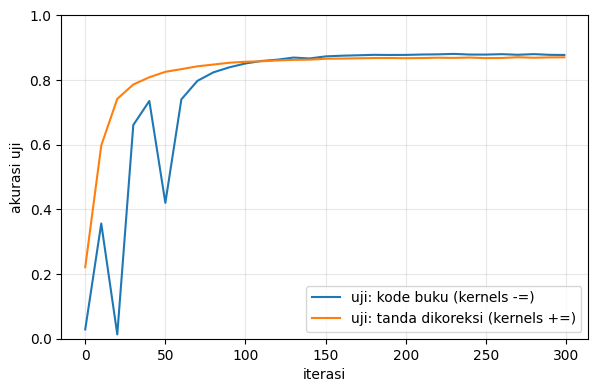

Akurasi uji akhir  | kode buku : 0.8774 | tanda dikoreksi : 0.8702
Akurasi uji pada iterasi 20 | kode buku : 0.0133 | tanda dikoreksi : 0.7417


In [7]:
# Tambahan (tidak ada di buku): pelatihan identik dengan tanda update kernel dikoreksi (+=)
def latih_cnn(tanda, iterations=300, seed=1):
    np.random.seed(seed)
    _k = 0.02 * np.random.random((kernel_rows * kernel_cols, num_kernels)) - 0.01
    _w = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1
    hist = []
    for j in range(iterations):
        correct = 0
        for i in range(int(len(images) / batch_size)):
            bs_, be_ = i * batch_size, (i + 1) * batch_size
            l0 = images[bs_:be_].reshape(-1, 28, 28)
            flat, es = expand_batch(l0)
            ko = flat.dot(_k)
            l1 = tanh(ko.reshape(es[0], -1))
            mask = np.random.randint(2, size=l1.shape); l1 *= mask * 2
            l2 = softmax(np.dot(l1, _w))
            correct += int(np.sum(np.argmax(l2, 1) == np.argmax(labels[bs_:be_], 1)))
            d2 = (labels[bs_:be_] - l2) / (batch_size * l2.shape[0])
            d1 = d2.dot(_w.T) * tanh2deriv(l1); d1 *= mask
            _w += alpha * l1.T.dot(d2)
            _k = _k + tanda * alpha * flat.T.dot(d1.reshape(ko.shape))     # tanda=+1 koreksi, -1 seperti buku
        if j % 10 == 0 or j == iterations - 1:
            hist.append((j, evaluasi(_k, _w, test_images, test_labels), correct / float(len(images))))
    return _k, _w, np.array(hist)

t0 = time.time()
kernels_fix, w12_fix, h_fix = latih_cnn(+1)
print('waktu: %.0f detik' % (time.time() - t0))
h_buku = np.array(riwayat_buku)

plt.figure(figsize=(6.8, 4.2))
plt.plot(h_buku[:, 0], h_buku[:, 1], label='uji: kode buku (kernels -=)')
plt.plot(h_fix[:, 0],  h_fix[:, 1],  label='uji: tanda dikoreksi (kernels +=)')
plt.xlabel('iterasi'); plt.ylabel('akurasi uji'); plt.ylim(0.0, 1.0); plt.grid(alpha=0.3); plt.legend(); plt.show()
print(f'Akurasi uji akhir  | kode buku : {h_buku[-1, 1]:.4f} | tanda dikoreksi : {h_fix[-1, 1]:.4f}')
print(f'Akurasi uji pada iterasi 20 | kode buku : {h_buku[2, 1]:.4f} | tanda dikoreksi : {h_fix[2, 1]:.4f}')

**Interpretasi:** pada iterasi ke-20, versi dengan tanda yang dikoreksi sudah mencapai akurasi uji ≈ 74,1%, sedangkan versi buku baru ≈ 1,3% (di bawah tebakan acak): kernel awalnya bergerak ke arah yang **menaikkan error**. Namun pada iterasi ke-300 kedua versi hampir setara (buku ≈ 87,8%, dikoreksi ≈ 87,0%): layer output dengan 100.000 bobot tetap bisa belajar, dan kernel versi buku tumbuh besar (norma rata-rata ≈ 1,02 dibanding ≈ 0,30) sampai menghasilkan fitur yang masih cukup informatif. Jadi tanda yang tidak konsisten tidak membuat jaringan gagal total, tetapi membuat belajar jauh lebih lambat dan sulit diandalkan. (Hasil ini dari satu *seed*; selisih akhir 0,75 poin persentase terlalu kecil untuk disimpulkan sebagai perbedaan nyata.) Ini contoh penting: **tanda delta dan tanda pembaruan harus konsisten**, dan hasil yang "cukup baik" tidak membuktikan kodenya benar.

---
## 6. Melihat Kernel yang Dipelajari *(Tambahan)*

Setiap kernel 3×3 dapat divisualisasikan sebagai gambar kecil. Pada kernel yang berhasil dilatih, kita mengharapkan bobot yang lebih besar dan terstruktur dibanding kernel awal yang hampir 0 dan acak.

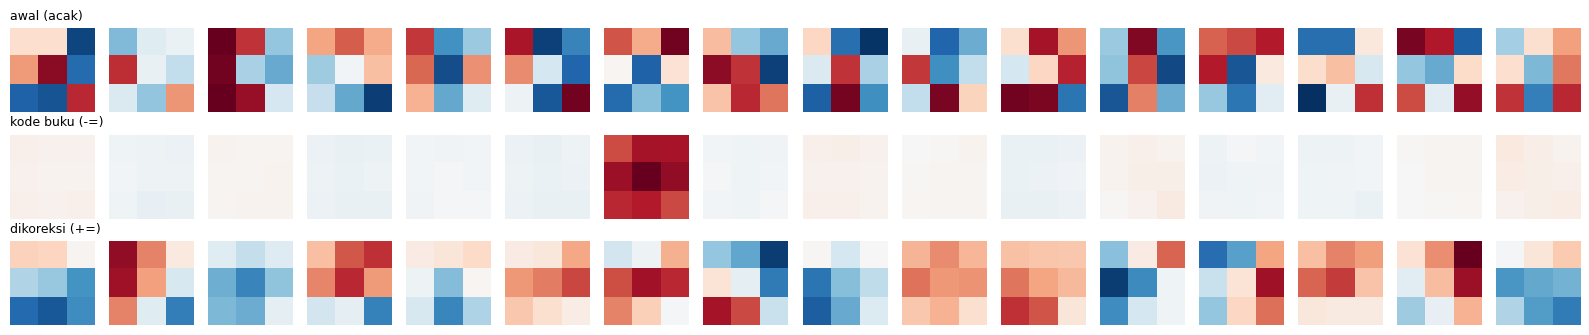

norma rata-rata kernel | awal: 0.018 | kode buku: 1.029 | dikoreksi: 0.302


In [8]:
# Tambahan (tidak ada di buku): kernel awal, kernel kode buku, dan kernel terkoreksi
np.random.seed(1)
kernels_awal = 0.02 * np.random.random((9, 16)) - 0.01

fig, axes = plt.subplots(3, 16, figsize=(16, 3.4))
for r, (nm, K) in enumerate([('awal (acak)', kernels_awal), ('kode buku (-=)', kernels_buku), ('dikoreksi (+=)', kernels_fix)]):
    for c in range(16):
        k = K[:, c].reshape(3, 3)
        axes[r, c].imshow(k, cmap='RdBu', vmin=-np.abs(K).max(), vmax=np.abs(K).max()); axes[r, c].axis('off')
    axes[r, 0].set_title(nm, loc='left', fontsize=9)
plt.tight_layout(); plt.show()
print('norma rata-rata kernel | awal: %.3f | kode buku: %.3f | dikoreksi: %.3f' %
      tuple(np.linalg.norm(K, axis=0).mean() for K in (kernels_awal, kernels_buku, kernels_fix)))

**Interpretasi:** skala warna tiap baris dinormalisasi terhadap nilai maksimum barisnya sendiri, jadi bandingkan **norma rata-rata**: kernel awal ≈ 0,018, kernel versi buku ≈ 1,021, kernel versi terkoreksi ≈ 0,302. Kedua versi bergerak jauh dari nilai awal, tetapi pada versi buku kernel tumbuh jauh lebih besar karena pembaruannya mengikuti arah yang menaikkan error, bukan menurunkannya.

### Perbandingan dengan jaringan padat
Untuk konteks, jaringan padat dengan hidden layer 100 node (tanh + softmax + dropout + batch, kondisi serupa Bab 9) dilatih pada data yang sama.

In [9]:
# Tambahan (tidak ada di buku): baseline jaringan padat (Bab 9) dengan jumlah iterasi sama
def latih_padat(iters=300, hidden=100, batch=128, alpha=2, seed=1):
    rng = np.random.RandomState(seed)
    w01 = 0.02 * rng.random_sample((784, hidden)) - 0.01
    w12 = 0.2 * rng.random_sample((hidden, 10)) - 0.1
    for _ in range(iters):
        for s in range(0, (len(images) // batch) * batch, batch):
            l0 = images[s:s+batch]; l1 = np.tanh(l0 @ w01)
            mask = rng.randint(2, size=l1.shape); l1 = l1 * mask * 2
            l2 = softmax(l1 @ w12)
            d2 = (labels[s:s+batch] - l2) / (batch * l2.shape[0])
            d1 = d2 @ w12.T * (1 - l1 ** 2) * mask
            w12 += alpha * l1.T @ d2; w01 += alpha * l0.T @ d1
    return float((np.argmax(np.tanh(test_images @ w01) @ w12, 1) == np.argmax(test_labels, 1)).mean())

acc_padat = latih_padat()
print(f'Akurasi uji | padat (100 hidden): {acc_padat:.4f} | CNN kode buku: {h_buku[-1,1]:.4f} | CNN terkoreksi: {h_fix[-1,1]:.4f}')
print(f'Jumlah bobot | padat: {784*100 + 100*10:,} | CNN: {9*16 + 10000*10:,}')

Akurasi uji | padat (100 hidden): 0.8574 | CNN kode buku: 0.8774 | CNN terkoreksi: 0.8702
Jumlah bobot | padat: 79,400 | CNN: 100,144


**Interpretasi:** akurasi uji jaringan padat (100 hidden) ≈ 85,7%, CNN versi buku ≈ 87,8%, CNN terkoreksi ≈ 87,0%. CNN sedikit lebih baik (1–2 poin persentase) walau jumlah bobotnya juga sedikit lebih banyak (100.144 vs 79.400), dan sebagian besar bobot CNN berada di layer output. Perbedaan ini kecil dan berasal dari satu *seed*, jadi jangan dibaca sebagai bukti kuat; kelebihan konvolusi yang lebih jelas adalah efisiensi parameter pada layer pertama (144 bobot vs ±7,8 juta untuk jumlah hidden node yang sama).

---
## 7. Tanya-Jawab Konsep dan Latihan

**1. Apa ide utama *convolutional layer*?** Menggunakan ulang kumpulan bobot kecil (kernel) pada banyak posisi, sehingga pola yang sama terdeteksi di mana pun.

**2. Mengapa konvolusi mengurangi *overfitting*?** Parameter jauh lebih sedikit dan setiap kernel dilatih dari banyak posisi sekaligus; arsitekturnya memasukkan asumsi bahwa pola lokal berlaku di seluruh gambar.

**3. Apa itu *feature map*?** Hasil menggeser satu kernel ke seluruh posisi gambar; tiap nilai menyatakan seberapa kuat pola kernel muncul di posisi itu.

**4. Berapa jumlah bobot layer konvolusi di bab ini?** 3×3×16 = 144, dibanding ±7,8 juta bila memakai layer padat dengan jumlah hidden node yang sama.

**5. Mengapa kernel yang sama dapat menerima gradien dari banyak posisi?** Karena bobot yang sama dipakai di 625 posisi; gradiennya adalah **jumlah** kontribusi semua posisi (itulah `flattened_input.T.dot(l1d_reshape)`).

**6. Mengapa tanda update kernel harus konsisten dengan tanda delta?** Delta `target − prediksi` menunjuk ke arah penurunan error; pembaruan harus menambah (`+=`) searah delta tersebut. Tanda sebaliknya menaikkan error.

### Latihan mandiri
1. Bandingkan jumlah parameter dan ukuran hidden untuk `num_kernels = 4, 16, 32`.
2. Hitung secara manual ukuran *feature map* untuk gambar 28×28, kernel 5×5, *stride* 1, tanpa padding.
3. Terapkan kernel Sobel vertikal pada gambar yang seluruhnya konstan. Apa hasilnya?

In [10]:
# Jawaban latihan mandiri (Tambahan)
print('1) jumlah parameter layer konvolusi per jumlah kernel:')
for nk in [4, 16, 32]:
    print(f'   {nk:3d} kernel -> {9 * nk:4d} bobot kernel | hidden = {25 * 25 * nk:,} node')

print('2) ukuran feature map (valid conv) = 28 - 5 + 1 =', 28 - 5 + 1, '-> 24 x 24')

konstan = np.full((1, 28, 28), 0.7)
flat_k, _ = expand_batch(konstan)
print('3) Sobel vertikal pada gambar konstan: nilai maksimum |hasil| =', np.abs(flat_k.dot(kernel_vert.reshape(9))).max(), '(tidak ada tepi -> 0)')

1) jumlah parameter layer konvolusi per jumlah kernel:
     4 kernel ->   36 bobot kernel | hidden = 2,500 node
    16 kernel ->  144 bobot kernel | hidden = 10,000 node
    32 kernel ->  288 bobot kernel | hidden = 20,000 node
2) ukuran feature map (valid conv) = 28 - 5 + 1 = 24 -> 24 x 24
3) Sobel vertikal pada gambar konstan: nilai maksimum |hasil| = 0.0 (tidak ada tepi -> 0)


---
## 8. Ringkasan Bab

- **Ide inti:** gunakan ulang bobot yang sama (kernel kecil) di banyak posisi gambar; pola seperti tepi dan sudut dapat dideteksi di mana pun.
- ***Convolutional layer*:** geser kernel 3×3 ke seluruh gambar → *feature map*; gunakan banyak kernel; ratakan; lalu layer padat ke output.
- Parameter turun drastis (144 vs ±7,8 juta) → generalisasi lebih baik dan lebih tahan *overfitting*.
- Pada kode buku, tanda update kernel (`-=`) tidak konsisten dengan arah delta (`target − prediksi`). Pada percobaan di notebook ini, versi terkoreksi (`+=`) belajar jauh lebih cepat di awal (74% vs 1% pada iterasi ke-20), sementara akurasi akhir keduanya setara (≈ 87%).

### Rangkuman konsep
| Subbab | Konsep | Kode |
|---|---|---|
| Reuse bobot | Kernel dipakai ulang | `kernels` (9×16) |
| Kernel & feature map | Dot product potongan 3×3 | `get_image_section`, `flattened_input.dot(kernels)` |
| Alur shape | (batch, 625, 3, 3) → (batch×625, 9) → (batch, 10.000) | `reshape` |
| Pelatihan | tanh, softmax, dropout, mini-batch | `alpha = 2`, `batch_size = 128` |
| Update kernel | Jumlah gradien dari semua posisi | `flattened_input.T.dot(l1d_reshape)` |